# PREDICCION DEL NO2 A 24 HS

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
spark.sql ("SHOW TABLES in gold").show()

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


+---------+----------------+-----------+
|namespace|       tableName|isTemporary|
+---------+----------------+-----------+
|     gold|            aire|      false|
|     gold|dim_contaminante|      false|
|     gold|    dim_distrito|      false|
|     gold|      dim_espira|      false|
|     gold|    dim_estacion|      false|
|     gold|   dim_sonometro|      false|
|     gold|      dim_tiempo|      false|
|     gold|       fact_aire|      false|
|     gold|      fact_meteo|      false|
|     gold|  fact_poblacion|      false|
|     gold| fact_prediccion|      false|
|     gold|      fact_ruido|      false|
|     gold|    fact_trafico|      false|
|     gold| fact_zona_verde|      false|
+---------+----------------+-----------+



## 1. Datos: NO2 horario por estación (2021-2025)

In [3]:
# Creamos vista con la informacion de la concentracion por estacion, dia, mes, año, hora 
spark.sql ("""
    CREATE OR REPLACE TEMP VIEW no2_horario AS
    SELECT a.id_estacion,
           t.fecha_hora,
           t.anio, t.mes, t.hora, t.dia_semana,
           CAST(t.es_festivo AS INT) as es_festivo,
           a.concentracion as no2
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c 
        ON a.id_contaminante = c.id_contaminante
        WHERE c.nombre = 'NO2'
        AND t.anio BETWEEN 2021 AND 2025
    """)

spark.sql ("SELECT COUNT(*) AS filas FROM no2_horario").show()
spark.sql("SELECT * FROM no2_horario LIMIT 5").show()

+------+
| filas|
+------+
|295204|
+------+



+-----------+-------------------+----+---+----+----------+----------+----+
|id_estacion|         fecha_hora|anio|mes|hora|dia_semana|es_festivo| no2|
+-----------+-------------------+----+---+----+----------+----------+----+
|   46250030|2021-01-04 16:00:00|2021|  1|  16|         1|         0|11.0|
|   46250030|2021-01-09 03:00:00|2021|  1|   3|         6|         0| 2.0|
|   46250030|2021-01-18 22:00:00|2021|  1|  22|         1|         0|60.0|
|   46250030|2021-02-04 00:00:00|2021|  2|   0|         4|         0|27.0|
|   46250030|2021-02-15 04:00:00|2021|  2|   4|         1|         0| 1.0|
+-----------+-------------------+----+---+----+----------+----------+----+



In [4]:
# Para cada fila, necesitamos poner el NO2 del dia anterior de la misma estacion
spark.sql("""
    CREATE OR REPLACE TEMP VIEW datos_modelo AS
    SELECT hoy.*,
           ayer.no2 AS no2_ayer
    FROM no2_horario hoy
    JOIN no2_horario ayer
        ON  ayer.id_estacion = hoy.id_estacion
        AND ayer.fecha_hora  = hoy.fecha_hora - INTERVAL 24 HOURS
""")

spark.sql("SELECT COUNT(*) AS filas FROM datos_modelo").show()
spark.sql("SELECT id_estacion, fecha_hora, hora, no2, no2_ayer FROM datos_modelo LIMIT 5").show()

+------+
| filas|
+------+
|288710|
+------+



+-----------+-------------------+----+----+--------+
|id_estacion|         fecha_hora|hora| no2|no2_ayer|
+-----------+-------------------+----+----+--------+
|   46250050|2023-07-05 19:00:00|  19| 8.0|     7.0|
|   46250050|2023-11-20 13:00:00|  13|18.0|    48.0|
|   46250046|2024-09-09 13:00:00|  13|13.0|     6.0|
|   46250046|2024-11-21 11:00:00|  11|13.0|     6.0|
|   46250048|2021-04-24 21:00:00|  21| 7.0|     8.0|
+-----------+-------------------+----+----+--------+



Algunas filas se perdieron por falta de mediciones. 
6500 en total que representan solo un 2%

In [5]:
# Calculamos umbral de error dia por dia. Nuestro modelo de prediccion deberia ser mejor que ese umbral

spark.sql("""
    SELECT ROUND(AVG(ABS(no2-no2_ayer)),2) AS mae_referencia
    FROM datos_modelo
    WHERE anio= 2025
""").show()

+--------------+
|mae_referencia|
+--------------+
|          8.36|
+--------------+



## 3. Modelo: Gradient Boosting (Spark MLlib)

In [6]:
from pyspark.ml.feature import VectorAssembler

datos = spark.table("datos_modelo")

# Separamos entrenamiento (2021-2024) y test (2025)
train_horario = datos.filter("anio <= 2024")
test_horario  = datos.filter("anio = 2025")

# Juntamos las variables de entrada en una sola columna "features"
entradas = ["hora", "dia_semana", "mes", "es_festivo", "no2_ayer"]
ensamblador = VectorAssembler(inputCols=entradas, outputCol="features")

train_horario = ensamblador.transform(train_horario)
test_horario  = ensamblador.transform(test_horario)

print("Entrenamiento:", train_horario.count(), "filas")
print("Test:", test_horario.count(), "filas")

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Entrenamiento: 235836 filas


Test: 52874 filas


In [7]:
from pyspark.ml.regression import GBTRegressor #modelo de Gradient Boosting de Spark
from pyspark.ml.evaluation import RegressionEvaluator

# Creamos y entrenamos el modelo
gbt = GBTRegressor (featuresCol ="features", labelCol="no2", maxIter=50) # usa 50 árboles
modelo_gbt = gbt.fit (train_horario)

# Predecimos 2025
predicciones_2025 = modelo_gbt.transform (test_horario)

# Medimos el error
evaluador = RegressionEvaluator(labelCol="no2", predictionCol="prediction", metricName="mae")
mae_gbt = evaluador.evaluate (predicciones_2025)
print("MAE Gradient Boosting:", round(mae_gbt, 2), "µg/m³")

MAE Gradient Boosting: 7.16 µg/m³


El modelo se equivoca un 14 % menos que la referencia (MAE de 7,16 frente a 8,36 µg/m³).
La mejora es moderada. Es esperable porque el modelo no sabe el tiempo y el trafico de mañana. Con sólo el calendario y el día anterior, el modelo mejora la referencia. Pero para predecir mejor deberiamos incluir trafico o la meteorología del dia siguiente.

In [8]:
# Que variables usa el modelo?
for nombre, importancia in zip(entradas, modelo_gbt.featureImportances):
    print(nombre, ":", round(importancia * 100, 1), "%")

hora : 23.8 %
dia_semana : 15.5 %
mes : 17.5 %
es_festivo : 4.7 %
no2_ayer : 38.4 %


La variable más importante es el NO2 del día anterior (38 %), seguida de la hora (24 %), el mes (18 %) y el día de la semana (16 %). El modelo usa los mismos patrones que encontramos en el análisis temporal: el ciclo diario, la estacionalidad y el efecto fin de semana. Los festivos pesan poco (5 %) porque son pocos días al año.

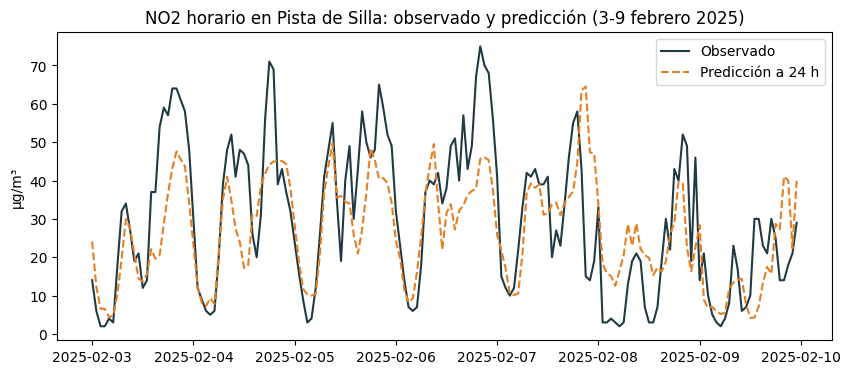

In [9]:
# Al intentar graficar nos dio error de compatibilidad entre la version de Spark del cluster y la de pandas.
# En este caso el error es con las fechas. Lo arregalmos
import io
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import storage

filas = (predicciones_2025
         .filter("id_estacion = '46250030' AND fecha_hora >= '2025-02-03' AND fecha_hora < '2025-02-10'")
         .select("fecha_hora", "no2", "prediction")
         .orderBy("fecha_hora")
         .collect())

semana = pd.DataFrame(filas, columns=["fecha_hora", "no2", "prediction"])

plt.figure(figsize=(10, 4))
plt.plot(semana["fecha_hora"], semana["no2"], color="#203A43", label="Observado")
plt.plot(semana["fecha_hora"], semana["prediction"], color="#E67E22", linestyle="--", label="Predicción a 24 h")
plt.title("NO2 horario en Pista de Silla: observado y predicción (3-9 febrero 2025)")
plt.ylabel("µg/m³")
plt.legend()

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/no2_prediccion_24h_pista_silla.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

El modelo acierto el ritmo diario. Se equivoca en los picos y entre viernes y sabado, porque se guía por el NO2 del día anterior.

**Conclusión:** El modelo Gradient Boosting predice el NO2 de cada estación con 24 horas de anticipación usando sólo el calendario y el NO2 del dñia anterior. Se entrenó con 2021-2024 (235.836 horas) y se evaluó con 2025 (52.874 horas).

Se equivoca un 14% menos que la referencia (MAE de 7,16 frente a 8,36 µg/m³). Acierta el ritmo diario, pero suaviza los picos altos y el cambio viernes-sábado.

Para mejorarlo habría que incluir una previsón del tráfico o de la meteorología del día siguiente.

## 4. Guardar las predicciones en fact_prediccion

In [16]:
# Guardamos en la GOLD
predicciones_2025.createOrReplaceTempView ("prediccion_24h")

spark.sql("""
    INSERT INTO gold.fact_prediccion
    SELECT 'gradient_boosting'                                AS modelo,
           'no2'                                              AS indicador,
           '24h'                                              AS horizonte,
           'horaria'                                          AS granularidad,
           CURRENT_DATE()                                     AS fecha_ejecucion,
           TO_DATE(fecha_hora)                                AS fecha_prevista,
           CAST(DATE_FORMAT(fecha_hora, 'yyyyMMddHH') AS INT) AS id_tiempo,
           id_estacion,
           ROUND(prediction, 1)                               AS valor_previsto,
           CAST(NULL AS DOUBLE)                               AS valor_bajo,
           CAST(NULL AS DOUBLE)                               AS valor_alto,
           CAST (NULL AS INT)                                 AS id_distrito
    FROM prediccion_24h
""")

spark.sql("SELECT modelo, COUNT(*) AS filas FROM gold.fact_prediccion GROUP BY modelo").show()

+-----------------+-----+
|           modelo|filas|
+-----------------+-----+
|gradient_boosting|52874|
|         sarima_b|   60|
| regresion_lineal|    5|
+-----------------+-----+

